# Projet ML - Classification binaire : **Spambase**


Ce notebook applique le workflow défini dans `ml_workflow.py` au jeu de données **Spambase** (UCI) : détecter si un e-mail est un spam (`1`) ou non (`0`) à partir de 57 fréquences de mots / caractères.

**Workflow** : import → nettoyage / pré-traitement (valeurs manquantes, centrage-réduction, ACP) → split train/test → entraînement avec sélection de variables → validation.

> **Règle suivie** : toutes les décisions (choix du modèle, du nombre de variables, des hyperparamètres) sont prises par **validation croisée sur le train uniquement**. Le jeu de test n'est utilisé qu'à la fin, pour l'évaluation finale.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import ml_workflow as ml

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
SEED = ml.RANDOM_STATE

## 1. Import et description des données  


In [2]:
# Loading data
df_spam = ml.load_spambase()

# what it looks like
display(df_spam.head())

# Dimension
print("Dimensions :", df_spam.shape)

# General description
display(ml.describe_dataset(df_spam, "is_spam"))

# Target distribution
display(df_spam["is_spam"].value_counts())

# percentage distribution
display(
    df_spam["is_spam"]
    .value_counts(normalize=True)
    .mul(100)
)


X_spam, y_spam = ml.split_features_target(
    df_spam,
    "is_spam"
)

print("X :", X_spam.shape)
print("y :", y_spam.shape)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


Dimensions : (4601, 58)


n_rows                                                          4601
n_columns                                                         58
n_features                                                        57
n_missing_values                                                   0
n_duplicated_rows                                                391
target                                                       is_spam
class_counts                                      {0: 2788, 1: 1813}
class_proportions    {0: 0.6059552271245382, 1: 0.39404477287546186}
dtype: object

is_spam
0    2788
1    1813
Name: count, dtype: int64

is_spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64

X : (4601, 57)
y : (4601,)


## 2. Split train / test (stratifié)  

In [3]:
# Missing values simulation
X_spam_missing = ml.inject_missing_values(
    X_spam,
    frac=0.05,
    seed=SEED
)

# Stratified train/test split
X_train_spam, X_test_spam, y_train_spam, y_test_spam = ml.split_data(
    X_spam_missing,
    y_spam,
    test_size=0.2,
    seed=SEED
)

print("Train :", X_train_spam.shape)
print("Test :", X_test_spam.shape)

print("\nDistribution du train :")
display(y_train_spam.value_counts(normalize=True))

print("\nDistribution du test :")
display(y_test_spam.value_counts(normalize=True))

print("\nValeurs manquantes dans le train :")
print(X_train_spam.isna().sum().sum())

print("\nValeurs manquantes dans le test :")
print(X_test_spam.isna().sum().sum())

Train : (3680, 57)
Test : (921, 57)

Distribution du train :


is_spam
0    0.605978
1    0.394022
Name: proportion, dtype: float64


Distribution du test :


is_spam
0    0.605863
1    0.394137
Name: proportion, dtype: float64


Valeurs manquantes dans le train :
10415

Valeurs manquantes dans le test :
2698


## 3. Pré-traitement  

In [4]:
# Pipeline showing
baseline_pipeline_spam = ml.build_pipeline(
    model=LogisticRegression(max_iter=1000),
    imputer_strategy="median",
    scale=True,
    selector=None,
    pca_components=None
)

# Structure
display(baseline_pipeline_spam)

print("\nÉtapes du pipeline :")
print(baseline_pipeline_spam.named_steps)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True



Étapes du pipeline :
{'imputer': SimpleImputer(strategy='median'), 'scaler': StandardScaler(), 'selector': 'passthrough', 'pca': 'passthrough', 'model': LogisticRegression(max_iter=1000)}


## 4. Comparaison de plusieurs méthodes de classification  

In [8]:
models = ml.get_models(
    class_weight="balanced",
    include_svm=True,
    random_state=SEED,
)

model_comparison = ml.cross_validate_models(
    models,
    X_train_spam,
    y_train_spam,
    cv=5,
    scoring=("f1", "roc_auc", "average_precision"),
)

display(
    model_comparison
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)

,roc_auc_mean,roc_auc_std,fit_time_s
lr,0.970096,0.006091,0.046183
rf,0.984239,0.003889,0.803259
hgb,0.986012,0.002895,0.590537
SVM-RBF,0.971243,0.003906,0.149800


## 5. Comparaison des methodes de selection de variables

Chaque methode est evaluee avec plusieurs nombres de variables. Le critere principal est la **PR-AUC moyenne** (`average_precision`) obtenue en validation croisee sur le jeu d'entrainement.

In [16]:
selector_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)

selector_table = ml.compare_feature_selectors(
    selector_model,
    X_train_spam,
    y_train_spam,
    methods=("anova", "mutual_info", "l1", "rf"),
    k_values=(5, 10, 15, 20),
    cv=5,
    scoring="average_precision",
)

display(
    selector_table
    .round(3)
    .sort_values("average_precision_mean", ascending=False)
)

,,average_precision_mean,average_precision_std,fit_time_s
method,k,,,
l1,20,0.943,0.011,0.096
rf,20,0.937,0.009,0.782
mutual_info,20,0.934,0.009,0.507
rf,15,0.933,0.009,0.893
l1,15,0.933,0.023,0.089
mutual_info,15,0.931,0.009,0.528
anova,20,0.920,0.012,0.056
l1,10,0.920,0.020,0.083
anova,15,0.912,0.007,0.075


### Test de l'ACP

L'ACP a `0.95` conserve les axes necessaires pour expliquer 95 % de la variance. Elle est comparee a un pipeline sans ACP sur le meme jeu et avec le meme critere PR-AUC.

In [17]:
pca_table = ml.compare_pca(
    selector_model,
    X_train_spam,
    y_train_spam,
    pca_components=(None, 0.95),
    cv=5,
    scoring="average_precision",
)

display(pca_table.round(3).sort_values("average_precision_mean", ascending=False))

,average_precision_mean,average_precision_std,fit_time_s
none,0.948,0.012,0.040
0.95,0.945,0.013,0.039


## 6. Reglage du meilleur modele avec GridSearchCV

Le reglage est effectue exclusivement sur le jeu d'entrainement, avec la PR-AUC comme critere de selection. Le meilleur estimateur est refit sur tout le train.

In [ ]:
lr = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)
lr_pipe = ml.build_pipeline(
    lr,
    selector="l1",
    k=20,
)

lr_grid = ml.tune_model(
    lr_pipe,
    {"model__C": [0.01, 0.1, 1.0, 10.0]},
    X_train_spam,
    y_train_spam,
    scoring="average_precision",
    cv=5,
)

print("Meilleurs hyperparametres :", lr_grid.best_params_)
print("Meilleure PR-AUC moyenne :", round(lr_grid.best_score_, 3))

Meilleurs hyperparametres : {'model__C': 10.0}
Meilleure PR-AUC moyenne : 0.938


## 7. Entrainement final sur le train complet

Le pipeline retenu est evalue une seule fois sur le jeu de test. Les performances sont donnees au seuil par defaut puis a un seuil optimise par F1 sur les predictions hors echantillon du train.

In [19]:
final_pipeline = lr_grid.best_estimator_

oof = ml.oof_scores(
    final_pipeline,
    X_train_spam,
    y_train_spam,
    cv=5,
)
best_threshold = ml.find_best_threshold(
    y_train_spam,
    oof,
    metric="f1",
)

print(f"Seuil optimise sur le train (OOF) : {best_threshold:.3f}")

Seuil optimise sur le train (OOF) : 0.427


In [20]:
final_pipeline.fit(X_train_spam, y_train_spam)

final_results = pd.DataFrame({
    "seuil par defaut": ml.evaluate_model(
        final_pipeline, X_test_spam, y_test_spam
    ),
    f"seuil optimise ({best_threshold:.3f})": ml.evaluate_model(
        final_pipeline, X_test_spam, y_test_spam, threshold=best_threshold
    ),
}).T

display(final_results.round(3))

,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
seuil par defaut,0.904,0.898,0.887,0.868,0.877,0.799,0.961,0.932
seuil optimise (0.427),0.908,0.906,0.872,0.898,0.885,0.808,0.961,0.932


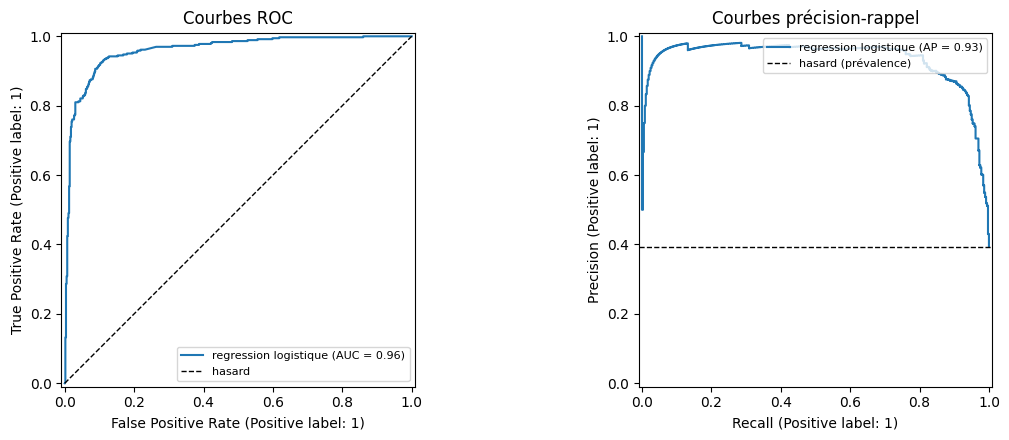

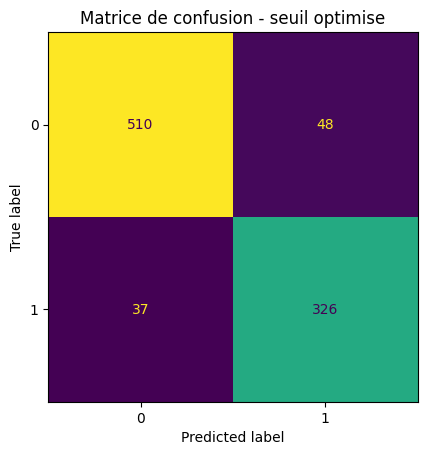

In [21]:
ml.plot_roc_pr(
    {"regression logistique": final_pipeline},
    X_test_spam,
    y_test_spam,
)

ml.plot_confusion(
    final_pipeline,
    X_test_spam,
    y_test_spam,
    threshold=best_threshold,
    title="Matrice de confusion - seuil optimise",
)

## 8. Conclusion

- Comparer les scores moyens et ecarts-types des methodes de selection.
- Justifier la methode et le nombre de variables retenus.
- Indiquer si l'ACP apporte une amelioration mesurable.
- Presenter les meilleurs hyperparametres et la PR-AUC obtenue.
- Comparer les performances finales au seuil par defaut et au seuil optimise.